# Real-brain PyG pilot: one animal, one 3D series

A small, end-to-end proof of concept on **real data**:

raw `.lif` image → existing Vistiq batch segmentation → per-object measurements → spatial relationships → PyTorch Geometric `Data` → one spatial clustering question.

Scope and caveats, stated up front:

- **One animal, one 3D image series.** Nothing here is a population-level finding.
- The default run **does not segment anything**. It loads the 3D labels written by Ivey's batch job (`ivey-batch/full-run`). An optional, off-by-default section shows how a fresh segmentation would be run; it needs a CUDA GPU.
- Manual ground truth here is **2D Dpn masks on selected planes only**. It is used to look at segmentation quality, not as 3D cells and not as EdU truth.
- Generated files go to `/home/tqv9uu/vistiqlab/outputs/real_brain_pyg_pilot`, outside the Git repo. Nothing under `/project` is modified.

Run with the **Python (Vistiq POC)** kernel.

## 0. Configuration

Change `ANIMAL` to run a different animal. Everything else (scene, series, channel) is looked up from Andy's GT manifest rather than assumed.

In [1]:
from pathlib import Path

ANIMAL = 1  # animal number in the file name Animal-<N>-scrib-edu-dpn.lif

RAW_DIR = Path("/project/vistiqlab/brain/24h/AkhGal4 x OR Susie/Scrib488 Dpn555 EdU 647/Raw files")
GT_DIR = RAW_DIR / "samples_for_gt"
BATCH_ROOT = Path("/project/vistiqlab/brain/jobruns/ivey-batch/full-run")
GT_RESULTS_DIR = Path("/project/vistiqlab/gt-results")
LOBE_ROOT = Path("/project/vistiqlab/brain/jobruns/lobe-segmentation/24h/AkhGal4 x OR Susie")
OUT_ROOT = Path("/home/tqv9uu/vistiqlab/outputs/real_brain_pyg_pilot")

# Channel identities used throughout Vistiq for this dataset (spatial-analysis.ipynb).
CHANNEL_RENAME = {"Red": "Dpn", "Green": "Scrib", "Blue": "EdU"}

K_NEIGHBORS = 5            # kNN edges among Dpn centroids
EDU_IOS_THRESHOLD = 0.5    # Dpn is EdU+ if any EdU object has IoS > this (spatial-analysis overlap_filter)
N_PERMUTATIONS = 2000      # label shuffles for the null distribution
SEED = 0
USE_LOBE_LABELS = True     # used only if a lobe file exists for this exact scene and its shape matches
N_GT_SLICES_TO_SHOW = 2

# Optional fresh segmentation (Section 2b). Off by default; requires a CUDA GPU.
RUN_SEGMENTATION = False

In [2]:
import json
import logging
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile
import torch
from bioio import BioImage
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from torch_geometric.data import Data
from torch_geometric.utils import coalesce, contains_self_loops, is_undirected, to_undirected

from vistiq.io import ImageLoader, ImageLoaderConfig
from vistiq.utils import ArrayIteratorConfig
from vistiq.segment import RegionAnalyzer, RegionAnalyzerConfig
from vistiq.analysis import (
    DistanceCalculator,
    DistanceCalculatorConfig,
    IoSMetricsCalculatorConfig,
    LabelOverlapCalculatorConfig,
    OverlapCalculator,
    region_map_from_dataframe,
)
from vistiq.matrix import MatrixFormatter, MatrixFormatterConfig, TopKFilter, TopKFilterConfig
from vistiq.matrix.types import OFF_DIAGONAL, matrix_to_numpy

# Vistiq/Prefect log every task at INFO; keep the notebook readable.
logging.getLogger().setLevel(logging.WARNING)
for name in ("vistiq", "prefect", "httpx"):
    logging.getLogger(name).setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning, module="vistiq")

rng = np.random.default_rng(SEED)
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())

torch 2.11.0+cu128 | CUDA available: False


## 1. Select and verify inputs

The GT manifest (`gt_series_manifest.csv`, from Andy's `match_gt_to_series.py` run) records which batch series each annotated slice was matched to, by image correlation. We use it to pick the series instead of assuming `scene N` ↔ `Series00(N+1)`. The mapping is then checked against the scene names inside the `.lif` file.

Every required file is checked; a missing one stops the notebook with a clear message.

In [3]:
def require(path, what):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Required {what} not found:\n  {path}")
    return path


PREFIX = f"Animal-{ANIMAL}-scrib-edu-dpn"
raw_path = require(RAW_DIR / f"{PREFIX}.lif", "raw .lif image")
manifest_path = require(GT_RESULTS_DIR / "gt_series_manifest.csv", "GT manifest (Andy's match_gt_to_series.py output)")

manifest = pd.read_csv(manifest_path)
gt_rows = manifest[(manifest["animal_prefix"] == PREFIX) & (manifest["status"] == "OK")].copy()
if gt_rows.empty:
    raise ValueError(f"No manifest rows with status OK for {PREFIX} in {manifest_path}")

for col in ("scene", "best_series", "best_channel"):
    if gt_rows[col].nunique() != 1:
        raise ValueError(f"{PREFIX}: GT slices map to more than one {col}: {sorted(gt_rows[col].unique())}")

SCENE_INDEX = int(gt_rows["scene"].iloc[0])
SERIES_DIR_NAME = gt_rows["best_series"].iloc[0]
GT_CHANNEL = gt_rows["best_channel"].iloc[0]
if CHANNEL_RENAME.get(GT_CHANNEL) != "Dpn":
    raise ValueError(f"Manifest matched GT to channel {GT_CHANNEL!r}, expected the Dpn channel (Red)")

# Scene index -> scene name inside the .lif, and the series name encoded in the batch folder.
lif_scenes = BioImage(raw_path).scenes
scene_name = lif_scenes[SCENE_INDEX]
series_name = SERIES_DIR_NAME.split("-(")[0]
if scene_name != series_name:
    raise ValueError(f"LIF scene {SCENE_INDEX} is {scene_name!r}, but the manifest's batch folder is {series_name!r}")
batch_shape = tuple(int(v) for v in re.search(r"\(([\d,]+)\)", SERIES_DIR_NAME).group(1).split(","))  # (T, C, Z, Y, X)

series_dir = require(BATCH_ROOT / f"{PREFIX}.lif" / PREFIX / SERIES_DIR_NAME, "batch series folder")
label_paths = {
    name: require(series_dir / f"Labels_{ch}.{ch}.tif", f"{name} ({ch}) predicted labels")
    for ch, name in CHANNEL_RENAME.items()
}
features_path = series_dir / "Features_Red.csv"                # batch per-Dpn table (optional, for unit checks)
batch_coinc_path = series_dir / "Coincidence_Red_Blue_vs_Red.csv"  # batch Dpn-vs-EdU calls (optional)

OUT_DIR = OUT_ROOT / f"{PREFIX}_{series_name}"
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Animal:            {PREFIX}")
print(f"Raw image:         {raw_path}")
print(f"LIF scenes:        {lif_scenes}")
print(f"Selected scene:    index {SCENE_INDEX} = {scene_name}")
print(f"Batch series dir:  {series_dir}")
print(f"Batch shape (TCZYX from folder name): {batch_shape}")
for name, p in label_paths.items():
    print(f"  {name:6s} labels: {p.name}")
print(f"GT slices for this animal (manifest): {len(gt_rows)} -> z = {sorted(gt_rows['best_z'].astype(int))}")
print(f"Outputs:           {OUT_DIR}")

Animal:            Animal-1-scrib-edu-dpn
Raw image:         /project/vistiqlab/brain/24h/AkhGal4 x OR Susie/Scrib488 Dpn555 EdU 647/Raw files/Animal-1-scrib-edu-dpn.lif
LIF scenes:        ('Series001', 'Series002', 'Series003')
Selected scene:    index 2 = Series003
Batch series dir:  /project/vistiqlab/brain/jobruns/ivey-batch/full-run/Animal-1-scrib-edu-dpn.lif/Animal-1-scrib-edu-dpn/Series003-(1,3,89,512,512)-DoG-MicroSAMSegmenter
Batch shape (TCZYX from folder name): (1, 3, 89, 512, 512)
  Dpn    labels: Labels_Red.Red.tif
  Scrib  labels: Labels_Green.Green.tif
  EdU    labels: Labels_Blue.Blue.tif
GT slices for this animal (manifest): 10 -> z = [13, 20, 24, 30, 31, 51, 52, 60, 67, 83]
Outputs:           /home/tqv9uu/vistiqlab/outputs/real_brain_pyg_pilot/Animal-1-scrib-edu-dpn_Series003


## 2. Load the raw image and the existing 3D segmentation

`ImageLoader` is configured the same way as in `spatial-analysis.ipynb`. The LIF reports the Z step as **negative** (stage direction). Physical distances only need its magnitude, so we keep the sign for the record and use `abs()` for spacing.

In [4]:
ilc = ImageLoaderConfig(
    squeeze=True,
    rename_channel=CHANNEL_RENAME,
    scene_index=SCENE_INDEX,
    split_channels=False,
)
img, metadata = ImageLoader(ilc).run(str(raw_path))

axes = list(metadata["axes"])
channel_names = list(metadata["channel_names"])
scale = metadata["scale"]
SPACING_ZYX = tuple(float(abs(getattr(scale, a))) for a in ("Z", "Y", "X"))
CH = {name: channel_names.index(name) for name in ("Dpn", "EdU", "Scrib")}

if axes != ["C", "Z", "Y", "X"]:
    raise ValueError(f"Expected CZYX after squeeze, got {axes}")
if img.shape != batch_shape[1:]:
    raise ValueError(f"Raw image shape {img.shape} does not match batch series shape {batch_shape[1:]}")

labels = {}
for name, p in label_paths.items():
    labels[name] = tifffile.imread(p)
    if labels[name].shape != img.shape[1:]:
        raise ValueError(f"{name} labels shape {labels[name].shape} != image ZYX shape {img.shape[1:]}")

print("Image shape (C,Z,Y,X):", img.shape, img.dtype)
print("Channel order in file:", channel_names, "-> index", CH)
print("Scale reported by LIF (Z,Y,X):", (scale.Z, scale.Y, scale.X), metadata.get("pixel_unit"))
print("Spacing used (um, Z,Y,X):", SPACING_ZYX)
for name, lab in labels.items():
    print(f"{name:6s} labels: shape={lab.shape} dtype={lab.dtype} objects={len(np.unique(lab)) - 1}")

Image shape (C,Z,Y,X): (3, 89, 512, 512) uint8
Channel order in file: ['Scrib', 'EdU', 'Dpn'] -> index {'Dpn': 2, 'EdU': 1, 'Scrib': 0}
Scale reported by LIF (Z,Y,X): (-0.9999285227272728, 0.19041731898238748, 0.19041731898238748) um
Spacing used (um, Z,Y,X): (0.9999285227272728, 0.19041731898238748, 0.19041731898238748)
Dpn    labels: shape=(89, 512, 512) dtype=uint16 objects=149
Scrib  labels: shape=(89, 512, 512) dtype=uint16 objects=482
EdU    labels: shape=(89, 512, 512) dtype=uint16 objects=405


Inline inspection: maximum-intensity projections of each raw channel, then one plane with predicted Dpn outlines. Raw data are 8-bit; display uses the 1st–99.8th percentile.

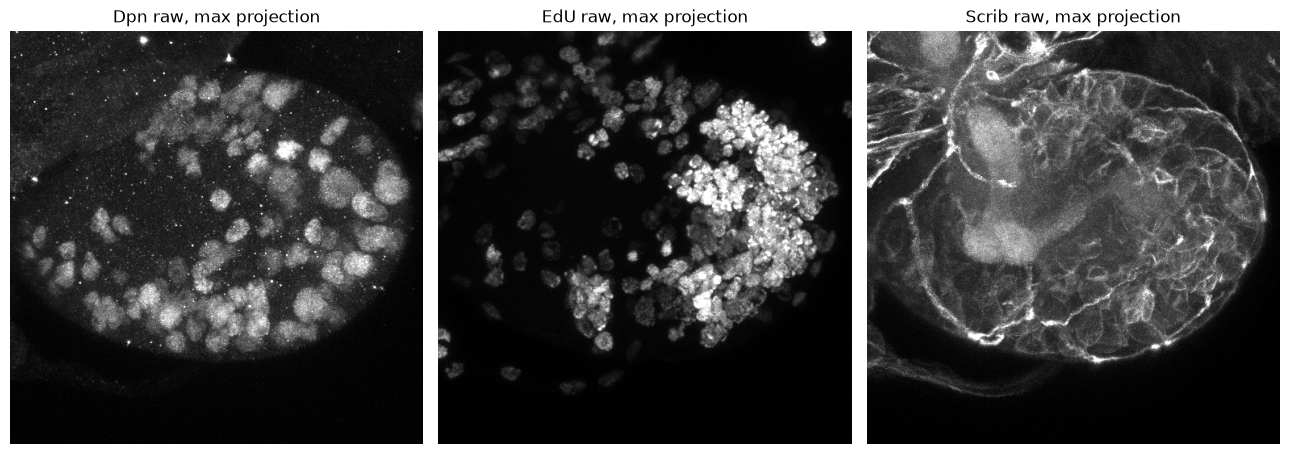

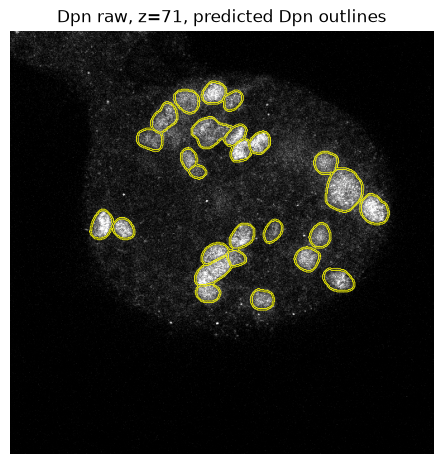

In [5]:
def stretch(a, lo=1, hi=99.8):
    a = a.astype(float)
    p0, p1 = np.percentile(a, [lo, hi])
    return np.clip((a - p0) / max(p1 - p0, 1e-9), 0, 1)


fig, axs = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, name in zip(axs, ("Dpn", "EdU", "Scrib")):
    ax.imshow(stretch(img[CH[name]].max(axis=0)), cmap="gray")
    ax.set_title(f"{name} raw, max projection")
    ax.axis("off")
plt.tight_layout()
plt.show()

z_show = int(np.argmax([(np.unique(s).size) for s in labels["Dpn"]]))
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.imshow(stretch(img[CH["Dpn"], z_show]), cmap="gray")
ax.contour(find_boundaries(labels["Dpn"][z_show]), levels=[0.5], colors="yellow", linewidths=0.6)
ax.set_title(f"Dpn raw, z={z_show}, predicted Dpn outlines")
ax.axis("off")
plt.show()

### 2b. Optional: fresh segmentation (off by default, needs a CUDA GPU)

This reproduces the **lobe (tissue)** and **cell** segmentation configuration from `spatial-analysis.ipynb` for this one scene and writes TIFFs to `OUT_DIR/rerun/`. It would also be the way to obtain lobe labels for a series that has none.

Notes:
- The configs below are built on every run (cheap, catches API errors). The MicroSAM work only runs when `RUN_SEGMENTATION = True`, and the cell refuses to start without CUDA.
- These are the `spatial-analysis.ipynb` settings. They are **not** the batch-job settings (DoG preprocessing, `vit_l_lm`, `volume_max`, dice coincidence), so rerun labels will not reproduce `full-run`.
- The rest of the notebook keeps using the batch labels unless you point `label_paths` at the rerun files.
- Not executed during this notebook's verification (no GPU on the node it was built on).

In [6]:
from vistiq.io import unstack_image
from vistiq.preprocess import FuncProcessorConfig, PreprocessFlow, PreprocessFlowConfig, RescaleConfig
from vistiq.segment import (
    MicroSAMSegmenterConfig,
    RangeFilterConfig,
    RegionFilterConfig,
    SegmentationFlow,
    SegmentationFlowConfig,
    TiledSegmentationFlow,
    TiledSegmentationFlowConfig,
)

RERUN_DIR = OUT_DIR / "rerun"
EMBEDDING_DIR = RERUN_DIR / "embeddings"

# Tissue (lobe) preprocessing + tiled segmentation: spatial-analysis.ipynb cells 9 and 13.
tissue_ppcfg = PreprocessFlowConfig(processors=[
    RescaleConfig(low=2, high=98, dtype=np.uint8, iterator_config=ArrayIteratorConfig(slice_def=(-3, -2, -1))),
    FuncProcessorConfig(func="skimage.filters.gaussian", kwargs={"sigma": 1.0}, iterator_config=ArrayIteratorConfig(slice_def=(-2, -1))),
    FuncProcessorConfig(func="skimage.exposure.adjust_gamma", kwargs={"gamma": 0.2}, iterator_config=ArrayIteratorConfig(slice_def=(-3, -2, -1))),
    FuncProcessorConfig(func="skimage.exposure.adjust_sigmoid", iterator_config=ArrayIteratorConfig(slice_def=(-3, -2, -1))),
    RescaleConfig(dtype=np.uint8, iterator_config=ArrayIteratorConfig(slice_def=(-3, -2, -1))),
    FuncProcessorConfig(func="numpy.max", kwargs={"axis": ("C")}, strict_axis=False, dtype=np.uint16),
])
tissue_tsfcfg = TiledSegmentationFlowConfig(
    segmenter=MicroSAMSegmenterConfig(iterator_config=ArrayIteratorConfig(slice_def=()), embedding_path=str(EMBEDDING_DIR / "tissue")),
    region_filter=RegionFilterConfig(filters=[
        RangeFilterConfig(attribute="cross_sectional_area-xy", range=(2000, np.inf)),
        RangeFilterConfig(attribute="cross_sectional_area-xz", range=(2000, np.inf)),
        RangeFilterConfig(attribute="cross_sectional_area-yz", range=(2000, np.inf)),
        RangeFilterConfig(attribute="aspect_ratio", range=(0.5, 1.0)),
    ]),
    tile_factor=(3, 3),
    resize_factor=(0.25, 0.25),
    iou_threshold=0.5,
    consensus_threshold=0.75,
)

# Cell segmentation per channel: spatial-analysis.ipynb cells 17-18.
min_cell_radius, max_cell_radius = 2.0, 7.0
cell_ppcfg = PreprocessFlowConfig(processors=[])
cell_sfcfg = SegmentationFlowConfig(
    segmenter=MicroSAMSegmenterConfig(iterator_config=ArrayIteratorConfig(slice_def=()), embedding_path=str(EMBEDDING_DIR / "cells")),
    region_filter=RegionFilterConfig(filters=[
        RangeFilterConfig(attribute="cross_sectional_area-xy", range=(np.pi * min_cell_radius**2, np.pi * max_cell_radius**2)),
    ]),
)
print("Rerun configs built. RUN_SEGMENTATION =", RUN_SEGMENTATION)

if RUN_SEGMENTATION:
    if not torch.cuda.is_available():
        raise RuntimeError("RUN_SEGMENTATION=True needs a CUDA GPU (MicroSAM). Start a GPU session or leave it False.")
    RERUN_DIR.mkdir(parents=True, exist_ok=True)

    tissue_img, tissue_md = PreprocessFlow(tissue_ppcfg).run(img, metadata=metadata, workers=-1)
    lobe_labels = np.asarray(TiledSegmentationFlow(tissue_tsfcfg).run(tissue_img, metadata=tissue_md, workers=2, verbose=0))
    if lobe_labels.ndim == 2:  # 2D tissue mask: repeat along Z, as full_pipeline does
        lobe_labels = np.repeat(lobe_labels[np.newaxis], img.shape[1], axis=0)
    tifffile.imwrite(RERUN_DIR / f"{PREFIX}-scene-{SCENE_INDEX}.Lobe.tif", lobe_labels.astype(np.uint16))

    pre, pre_md = PreprocessFlow(cell_ppcfg).run(img, metadata=metadata)
    chans, chan_md = unstack_image(pre, pre_md, axis=metadata["channel_axis"], strict=False)
    cell_labels = SegmentationFlow(cell_sfcfg).mapped_run(chans, metadata=chan_md, workers=1)
    for lab, md_ in zip(cell_labels, chan_md):
        tifffile.imwrite(RERUN_DIR / f"{PREFIX}-scene-{SCENE_INDEX}.{md_['channel_names'][0]}.tif", np.asarray(lab))
    print("Rerun labels written to", RERUN_DIR)

Rerun configs built. RUN_SEGMENTATION = False


## 3. Ground truth: what it is and how it is used here

Sarah's `*.dpn.gt.tif` files are **binary 2D masks of Dpn cells on ten selected z-planes** of one series per animal.

- They are **not** a 3D segmentation and they say **nothing about EdU status**.
- Binary masks are split into cells by connected components (as in `compute_gt_f1.py`), so touching annotated cells can merge.

We first confirm that the raw slice saved next to each mask is identical to the corresponding Dpn plane of the `.lif` we loaded, then overlay raw Dpn, manual mask and predicted Dpn outlines for a couple of slices, and show Andy's per-slice F1 rows (IoU ≥ 0.5 matching) for them.

GT raw slices identical to LIF Dpn plane at the manifest z: 10/10


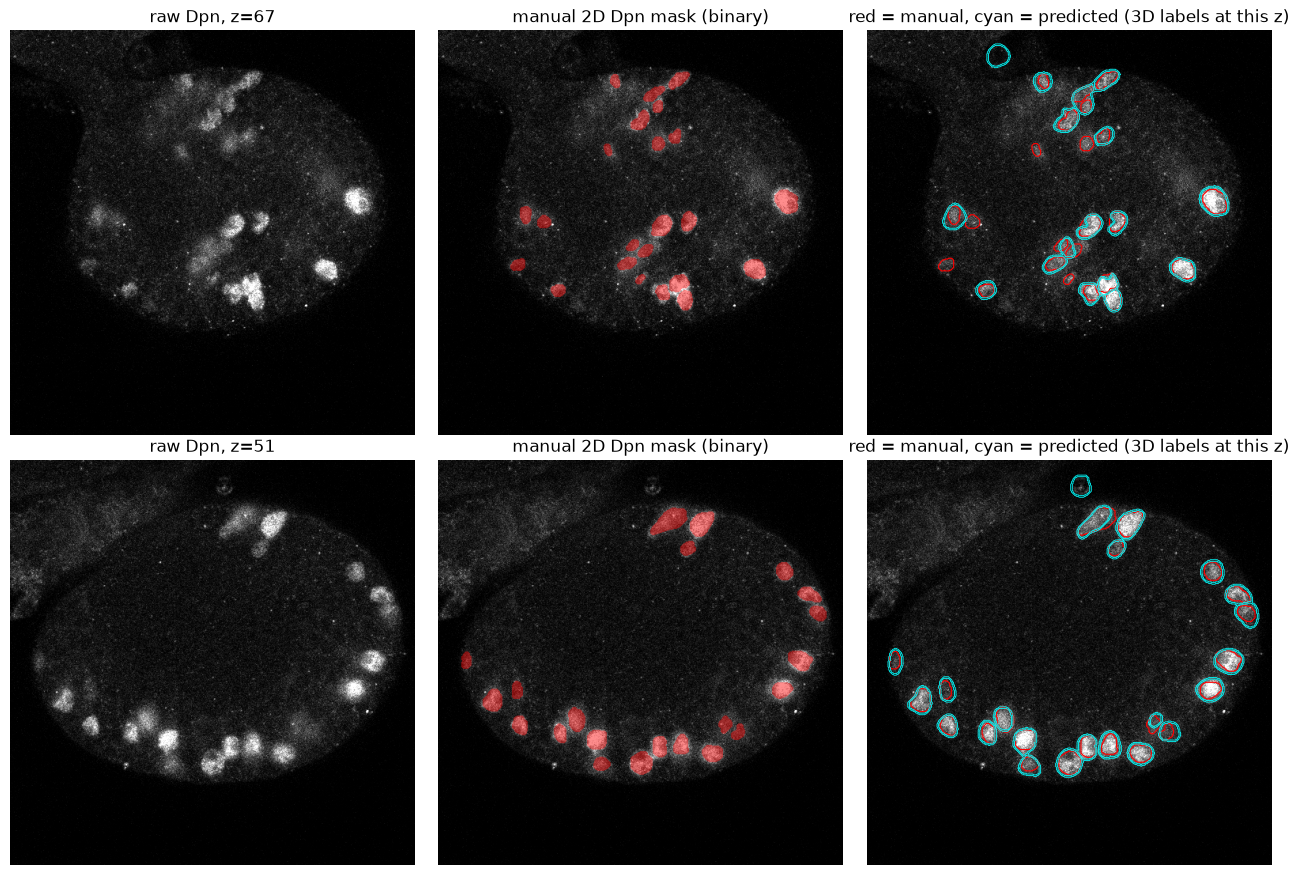

,gt_file,z,n_gt_cells,n_pred_cells,tp,fp,fn,precision,recall,f1
8,Animal-1-scrib-edu-dpn-scene-2.z-0067.dpn.gt.tif,67,23,17,12,5,11,0.705882,0.521739,0.600000
5,Animal-1-scrib-edu-dpn-scene-2.z-0051.dpn.gt.tif,51,22,23,19,4,3,0.826087,0.863636,0.844444


,animal_prefix,n_slices,tp,fp,fn,precision,recall,f1,mean_per_slice_f1
0,Animal-1-scrib-edu-dpn,10,95,42,52,0.693431,0.646259,0.669014,0.639289
12,OVERALL,120,941,486,698,0.659425,0.574131,0.613829,0.602197


In [7]:
gt_rows["best_z"] = gt_rows["best_z"].astype(int)
raw_check = []
for _, r in gt_rows.iterrows():
    raw_slice = tifffile.imread(require(GT_DIR / r["raw_file"], "GT raw slice"))
    raw_check.append(np.array_equal(raw_slice, img[CH["Dpn"], r["best_z"]]))
print(f"GT raw slices identical to LIF Dpn plane at the manifest z: {sum(raw_check)}/{len(raw_check)}")
if not all(raw_check):
    print("WARNING: some GT raw slices differ from this .lif scene; overlays below may be misaligned.")

per_slice_path = GT_RESULTS_DIR / "f1_per_slice.csv"
summary_path = GT_RESULTS_DIR / "f1_summary.csv"
per_slice = pd.read_csv(per_slice_path) if per_slice_path.exists() else None
f1_summary = pd.read_csv(summary_path) if summary_path.exists() else None

if per_slice is not None:
    animal_slices = per_slice[per_slice["animal_prefix"] == PREFIX].sort_values("n_gt_cells", ascending=False)
    show = animal_slices.head(N_GT_SLICES_TO_SHOW)
    show_files = list(show["gt_file"])
else:
    print("Andy's f1_per_slice.csv not found; showing the first manifest slices without F1.")
    show_files = list(gt_rows["gt_file"].head(N_GT_SLICES_TO_SHOW))

fig, axs = plt.subplots(len(show_files), 3, figsize=(13, 4.4 * len(show_files)), squeeze=False)
for row_axs, gt_file in zip(axs, show_files):
    r = gt_rows.set_index("gt_file").loc[gt_file]
    z = int(r["best_z"])
    raw_dpn = stretch(img[CH["Dpn"], z])
    gt_mask = tifffile.imread(GT_DIR / gt_file) > 0
    pred = labels["Dpn"][z]
    row_axs[0].imshow(raw_dpn, cmap="gray"); row_axs[0].set_title(f"raw Dpn, z={z}")
    row_axs[1].imshow(raw_dpn, cmap="gray"); row_axs[1].imshow(np.ma.masked_where(~gt_mask, gt_mask), cmap="autumn", alpha=0.45)
    row_axs[1].set_title("manual 2D Dpn mask (binary)")
    row_axs[2].imshow(raw_dpn, cmap="gray")
    row_axs[2].contour(gt_mask, levels=[0.5], colors="red", linewidths=0.8)
    row_axs[2].contour(find_boundaries(pred), levels=[0.5], colors="cyan", linewidths=0.6)
    row_axs[2].set_title("red = manual, cyan = predicted (3D labels at this z)")
    for ax in row_axs:
        ax.axis("off")
plt.tight_layout()
plt.show()

if per_slice is not None:
    display(show[["gt_file", "z", "n_gt_cells", "n_pred_cells", "tp", "fp", "fn", "precision", "recall", "f1"]])
if f1_summary is not None:
    display(f1_summary[f1_summary["animal_prefix"].isin([PREFIX, "OVERALL"])])

## 4. Graph nodes and regions

**Node = one 3D Dpn object** in the batch `Labels_Red` volume.

- Stable ID: the integer label in that TIFF (`dpn_label`) plus a readable `node_uid`. Vistiq's `object_id` is a random UUID regenerated on every `RegionAnalyzer` run, so it is kept only for reference.
- Measurements come from Vistiq's `RegionAnalyzer` with the physical spacing from the LIF.

**Unit check.** The batch `Features_Red.csv` centroids are compared with ours. If they match in Y/X and match in Z up to sign, the batch table is already in µm (with the LIF's negative Z step), and we must **not** multiply by the spacing again.

In [8]:
ra_cfg = RegionAnalyzerConfig(
    properties=["label", "volume", "centroid", "bbox", "aspect_ratio", "cross_sectional_area"],
    iterator_config=ArrayIteratorConfig(slice_def=()),
    output_type="dataframe",
    index_on="object_id",
    map_axes=True,
)
dpn_md = {"axes": ["Z", "Y", "X"], "scale": SPACING_ZYX, "channel_names": ["Dpn"]}
dpn_regions = RegionAnalyzer(ra_cfg).run(labels["Dpn"], metadata=dpn_md)

nodes = dpn_regions.reset_index().rename(columns={"label": "dpn_label"}).sort_values("dpn_label").reset_index(drop=True)
nodes["dpn_label"] = nodes["dpn_label"].astype(int)
nodes["node_uid"] = [f"{PREFIX}|{series_name}|Dpn|{l}" for l in nodes["dpn_label"]]
nodes["mean_dpn_intensity"] = ndi.mean(img[CH["Dpn"]], labels=labels["Dpn"], index=nodes["dpn_label"].to_numpy())
nodes["voxels"] = ndi.sum(np.ones_like(labels["Dpn"], dtype=np.uint8), labels=labels["Dpn"], index=nodes["dpn_label"].to_numpy())
POS_COLS = ["centroid-z", "centroid-y", "centroid-x"]

# Units: pixel-index centroid times spacing must equal RegionAnalyzer's centroid.
pix_centroids = np.array(ndi.center_of_mass(labels["Dpn"] > 0, labels["Dpn"], nodes["dpn_label"].to_numpy()))
assert np.allclose(pix_centroids * np.array(SPACING_ZYX), nodes[POS_COLS].to_numpy(), atol=1e-3), "RegionAnalyzer centroids are not pixel*spacing"
print("RegionAnalyzer centroids = pixel centroid x spacing (um): OK")

if features_path.exists():
    batch_feat = pd.read_csv(features_path).set_index("label")
    cmp = nodes.set_index("dpn_label")[POS_COLS + ["volume"]].join(batch_feat[["centroid-0", "centroid-1", "centroid-2", "volume"]], rsuffix="_batch", how="inner")
    dz = np.abs(np.abs(cmp["centroid-0"]) - cmp["centroid-z"]).max()
    dyx = np.abs(cmp[["centroid-1", "centroid-2"]].to_numpy() - cmp[["centroid-y", "centroid-x"]].to_numpy()).max()
    dv = np.abs(cmp["volume_batch"] - cmp["volume"]).max()
    print(f"Batch Features_Red.csv: {len(cmp)}/{len(nodes)} labels matched")
    print(f"  max |Y/X centroid diff| = {dyx:.4f} um, max ||Z| diff| = {dz:.4f} um, max volume diff = {dv:.4f} um^3")
    print(f"  batch Z centroids negative for {np.mean(cmp['centroid-0'] < 0):.0%} of objects (LIF Z step is negative)")
    if dyx < 1e-3 and dz < 1e-3:
        print("  -> batch centroids are already physical (um). We use our own positive-Z centroids; no extra scaling.")
else:
    print("Batch Features_Red.csv not present; unit comparison skipped.")

extent_um = np.array(img.shape[1:]) * np.array(SPACING_ZYX)
assert (nodes[POS_COLS].to_numpy() <= extent_um + 1e-6).all(), "centroids exceed the image extent: scaled twice?"
print("Image extent (um, Z,Y,X):", np.round(extent_um, 1), "| centroid max:", np.round(nodes[POS_COLS].max().to_numpy(), 1))
print("Dpn nodes:", len(nodes))

RegionAnalyzer centroids = pixel centroid x spacing (um): OK
Batch Features_Red.csv: 149/149 labels matched
  max |Y/X centroid diff| = 0.0000 um, max ||Z| diff| = 0.0000 um, max volume diff = 0.0000 um^3
  batch Z centroids negative for 100% of objects (LIF Z step is negative)
  -> batch centroids are already physical (um). We use our own positive-Z centroids; no extra scaling.
Image extent (um, Z,Y,X): [89.  97.5 97.5] | centroid max: [85.3 81.8 96.3]
Dpn nodes: 149


### Regions: lobe labels or a scene-level pilot graph?

Lobe labels are used only if a lobe file exists **for this exact scene index** in the lobe-segmentation batch and its shape matches the image. Each Dpn object is then assigned the lobe label that covers most of its voxels (label 0 = outside any lobe). Otherwise the whole series is one region, labelled `scene`, and per-lobe conclusions remain pending. Lobe assignments are never invented.

The lobe-segmentation batch has no record of which outputs are authoritative; treat them as candidates.

In [9]:
lobe_dir = LOBE_ROOT / f"{PREFIX}.lif"
lobe_path = lobe_dir / f"{PREFIX}-scene-{SCENE_INDEX}.Lobe.tif"
available = sorted(p.name for p in lobe_dir.glob("*.Lobe.tif")) if lobe_dir.exists() else []
print("Lobe files for this animal:", available or "none")

lobe_labels = None
if USE_LOBE_LABELS and lobe_path.exists():
    candidate = tifffile.imread(lobe_path)
    if candidate.shape == labels["Dpn"].shape:
        lobe_labels = candidate
        print(f"Using lobe labels: {lobe_path.name} (lobes: {[int(v) for v in np.unique(candidate) if v]})")
    else:
        print(f"Lobe file {lobe_path.name} has shape {candidate.shape} != {labels['Dpn'].shape}; not used.")
else:
    print(f"No lobe labels for scene {SCENE_INDEX} ({scene_name}).")

if lobe_labels is not None:
    def majority_lobe(dpn_label):
        vals, counts = np.unique(lobe_labels[labels["Dpn"] == dpn_label], return_counts=True)
        return int(vals[np.argmax(counts)])
    nodes["region"] = [f"lobe_{majority_lobe(l)}" for l in nodes["dpn_label"]]
    outside = nodes["region"] == "lobe_0"
    print(f"Dpn objects outside any lobe (excluded from graphs): {int(outside.sum())}")
    nodes = nodes[~outside].reset_index(drop=True)
    GRAPH_LEVEL = "lobe"
else:
    nodes["region"] = "scene"
    GRAPH_LEVEL = "scene"
    print("-> Building ONE scene-level pilot graph. Per-lobe conclusions are pending lobe labels for this series.")

display(nodes.groupby("region").size().rename("dpn_nodes").to_frame())

Lobe files for this animal: ['Animal-1-scrib-edu-dpn-scene-0.Lobe.tif']
No lobe labels for scene 2 (Series003).
-> Building ONE scene-level pilot graph. Per-lobe conclusions are pending lobe labels for this series.


,dpn_nodes
region,
scene,149


## 5. EdU status, edges and PyG objects

### EdU status (Vistiq overlap rule)

Vistiq's `OverlapCalculator` computes **IoS** (intersection over the *smaller* of the two objects) between every Dpn object and every EdU object in 3D. A Dpn object is **EdU+** if any EdU object has IoS > 0.5. This is the `overlap_filter` threshold used in `spatial-analysis.ipynb`, applied here directly to the Dpn × EdU matrix rather than through the containment hierarchy.

Direction: IoS is symmetric. It says that more than half of the *smaller* object lies inside the other. A small EdU fragment fully inside a large Dpn object therefore counts, even if it covers little of the Dpn volume. `dpn_frac_in_edu` (fraction of Dpn voxels inside any EdU object) is kept alongside, for inspection only.

The batch job used a different rule (`--method dice --threshold 0.1 --mode outline`); its calls from `Coincidence_Red_Blue_vs_Red.csv` are compared below. EdU status is an **observed attribute from segmentation**, with no EdU ground truth.

In [10]:
edu_regions = RegionAnalyzer(ra_cfg).run(labels["EdU"], metadata={**dpn_md, "channel_names": ["EdU"]})
dpn_all = dpn_regions.reset_index()  # all Dpn objects, so the matrix rows include every label

oc = OverlapCalculator(LabelOverlapCalculatorConfig(metrics_calculators=[IoSMetricsCalculatorConfig()], return_components=True))
overlap = oc.run(
    labels["Dpn"],
    labels["EdU"],
    region_map=(region_map_from_dataframe(dpn_all, axes=["Z", "Y", "X"]), region_map_from_dataframe(edu_regions.reset_index(), axes=["Z", "Y", "X"])),
    spacing=SPACING_ZYX,
)
fmt = MatrixFormatter(MatrixFormatterConfig(output_type="dataframe", annotate=True))
ios = fmt.run(overlap.metric("ios"))
inter = fmt.run(overlap.matrices["intersection"])

oid_to_label = dpn_all.set_index("object_id")["label"].astype(int)
ios.index = oid_to_label.loc[ios.index].to_numpy()
inter.index = ios.index
dpn_vol = dpn_all.set_index("label")["volume"]

edu_hits = (ios > EDU_IOS_THRESHOLD)
status = pd.DataFrame({
    "edu_pos": edu_hits.any(axis=1),
    "n_edu_overlaps": edu_hits.sum(axis=1),
    "max_ios_edu": ios.max(axis=1),
    "dpn_frac_in_edu": inter.sum(axis=1) / dpn_vol.loc[inter.index].to_numpy(),
})
nodes = nodes.drop(columns=[c for c in status.columns if c in nodes], errors="ignore").join(status, on="dpn_label")

print(f"EdU objects: {len(edu_regions)}; EdU objects with IoS>{EDU_IOS_THRESHOLD} to >1 Dpn object: {int((edu_hits.sum(axis=0) > 1).sum())}")
display(nodes.groupby("region")["edu_pos"].agg(n="size", edu_pos="sum", frac="mean"))

if batch_coinc_path.exists():
    batch_calls = pd.read_csv(batch_coinc_path).set_index("label")["Blue +"].rename("batch_dice_rule")
    agree = nodes.join(batch_calls, on="dpn_label")
    print("Agreement with the batch dice>0.1 outline rule (rows = IoS rule, cols = batch):")
    display(pd.crosstab(agree["edu_pos"], agree["batch_dice_rule"], dropna=False))

EdU objects: 405; EdU objects with IoS>0.5 to >1 Dpn object: 1


,n,edu_pos,frac
region,,,
scene,149,54,0.362416


Agreement with the batch dice>0.1 outline rule (rows = IoS rule, cols = batch):


batch_dice_rule,False,True
edu_pos,,
False,80,15
True,0,54


### Proximity edges (kNN)

Edges link each Dpn centroid to its `K_NEIGHBORS` nearest Dpn centroids **in µm**, computed with Vistiq's `DistanceCalculator` and `TopKFilter` (the same tools as `analyze-graph.ipynb`), **within each region only**. Directed kNN links are made undirected, so a node can have more than k neighbors.

These are **spatial proximity edges**: being near each other, not evidence of contact or communication. They are different from Vistiq's **containment/overlap** relationships (Dpn ⊃ EdU, IoS above), which are kept as a separate attribute (`dpn_edu_overlap`) and are not graph edges.

In [11]:
def knn_edges_vistiq(pos_um, k):
    # Directed kNN (i -> its k nearest j) via Vistiq; returns a (2, E) array of local indices.
    k = min(k, len(pos_um) - 1)
    if k < 1:
        return np.zeros((2, 0), dtype=np.int64)
    dist = DistanceCalculator(DistanceCalculatorConfig(preferred_device="cpu")).run(pos_um, pos_um, spacing=None)
    mask = np.asarray(matrix_to_numpy(
        TopKFilter(TopKFilterConfig(k=k, axis=1, largest=False, triangle=OFF_DIAGONAL, output="mask")).run(dist)
    ))
    src, dst = np.nonzero(mask)
    return np.stack([src, dst])


FEATURE_COLS = ["log_volume_um3", "aspect_ratio", "mean_dpn_intensity"]
nodes["log_volume_um3"] = np.log(nodes["volume"])

graphs = {}
for region, grp in nodes.groupby("region", sort=True):
    grp = grp.sort_values("dpn_label").reset_index(drop=True)
    pos = grp[POS_COLS].to_numpy(dtype=np.float32).copy()
    ei = torch.as_tensor(knn_edges_vistiq(pos, K_NEIGHBORS), dtype=torch.long)
    ei = coalesce(to_undirected(ei, num_nodes=len(grp)), num_nodes=len(grp))
    edge_len = torch.linalg.norm(torch.as_tensor(pos)[ei[0]] - torch.as_tensor(pos)[ei[1]], dim=1)

    dpn_idx = {l: i for i, l in enumerate(grp["dpn_label"])}
    ov = edu_hits.loc[grp["dpn_label"]]
    ov_pairs = [(dpn_idx[d], j) for d, row in zip(ov.index, ov.to_numpy()) for j in np.flatnonzero(row)]

    graphs[region] = Data(
        x=torch.as_tensor(grp[FEATURE_COLS].to_numpy(dtype=np.float32)),
        pos=torch.as_tensor(pos),
        edge_index=ei,
        edge_attr=edge_len.unsqueeze(1),
        edu_pos=torch.as_tensor(grp["edu_pos"].to_numpy(dtype=bool).copy()),
        dpn_label=torch.as_tensor(grp["dpn_label"].to_numpy(dtype=np.int64).copy()),
        dpn_edu_overlap=torch.as_tensor(ov_pairs, dtype=torch.long).reshape(-1, 2).T,
        node_uid=list(grp["node_uid"]),
        feature_names=FEATURE_COLS,
        edge_type="knn_proximity_um",
        k=K_NEIGHBORS,
        region=region,
        graph_level=GRAPH_LEVEL,
        animal=PREFIX,
        series=series_name,
        scene_index=SCENE_INDEX,
        spacing_zyx_um=SPACING_ZYX,
    )

for region, g in graphs.items():
    print(region, g)

scene Data(x=[149, 3], edge_index=[2, 930], edge_attr=[930, 1], pos=[149, 3], edu_pos=[149], dpn_label=[149], dpn_edu_overlap=[2, 64], node_uid=[149], feature_names=[3], edge_type='knn_proximity_um', k=5, region='scene', graph_level='scene', animal='Animal-1-scrib-edu-dpn', series='Series003', scene_index=2, spacing_zyx_um=[3])


**Node features `x`** (deliberately exclude anything EdU-derived):

| column | meaning |
|---|---|
| `log_volume_um3` | log of the 3D object volume in µm³ |
| `aspect_ratio` | Vistiq 3D aspect ratio (ratio of principal axis lengths, ≤ 1) |
| `mean_dpn_intensity` | mean raw 8-bit Dpn signal inside the object |

`pos` = centroid (z, y, x) in µm; `edge_attr` = edge length in µm; `edu_pos` = observed label (not in `x`); `dpn_edu_overlap` = (node index, EdU column index) pairs with IoS > 0.5.

**Checks**: node counts, index range, self-loops, duplicates, symmetry, cross-region edges, and agreement with an independent `scipy` kNN.

In [12]:
from scipy.spatial import cKDTree

for region, g in graphs.items():
    n = int((nodes["region"] == region).sum())
    ei = g.edge_index
    assert g.num_nodes == n == g.x.shape[0] == g.pos.shape[0], "node count mismatch"
    assert ei.numel() == 0 or (ei.min() >= 0 and ei.max() < n), "edge index out of range"
    assert not contains_self_loops(ei), "self loops present"
    assert coalesce(ei, num_nodes=n).shape == ei.shape, "duplicate edges present"
    assert is_undirected(ei, num_nodes=n), "graph not undirected"
    # every edge lies inside this region by construction; confirm via node_uid membership
    region_uids = set(nodes.loc[nodes["region"] == region, "node_uid"])
    assert set(g.node_uid) == region_uids, "graph contains nodes from another region"
    # independent kNN check
    k = min(K_NEIGHBORS, n - 1)
    _, idx = cKDTree(g.pos.numpy()).query(g.pos.numpy(), k=k + 1)
    ref = coalesce(to_undirected(torch.as_tensor(np.stack([np.repeat(np.arange(n), k), idx[:, 1:].ravel()]), dtype=torch.long), num_nodes=n), num_nodes=n)
    same = ref.shape == ei.shape and torch.equal(ref, ei)
    deg = torch.bincount(ei[0], minlength=n)
    print(f"[{region}] nodes={n} undirected edges={ei.shape[1] // 2} degree min/median/max="
          f"{int(deg.min())}/{float(deg.float().median()):.0f}/{int(deg.max())} "
          f"edge length median={float(g.edge_attr.median()):.1f} um | matches scipy kNN: {same}")

uid_region = dict(zip(nodes["node_uid"], nodes["region"]))
n_cross = sum(
    int(uid_region[g.node_uid[s]] != uid_region[g.node_uid[t]])
    for g in graphs.values() for s, t in g.edge_index.T.tolist()
)
print("Cross-region edges (endpoint regions looked up in the node table):", n_cross, "| graph level:", GRAPH_LEVEL)
assert n_cross == 0

[scene] nodes=149 undirected edges=465 degree min/median/max=5/6/10 edge length median=11.0 um | matches scipy kNN: True
Cross-region edges (endpoint regions looked up in the node table): 0 | graph level: scene


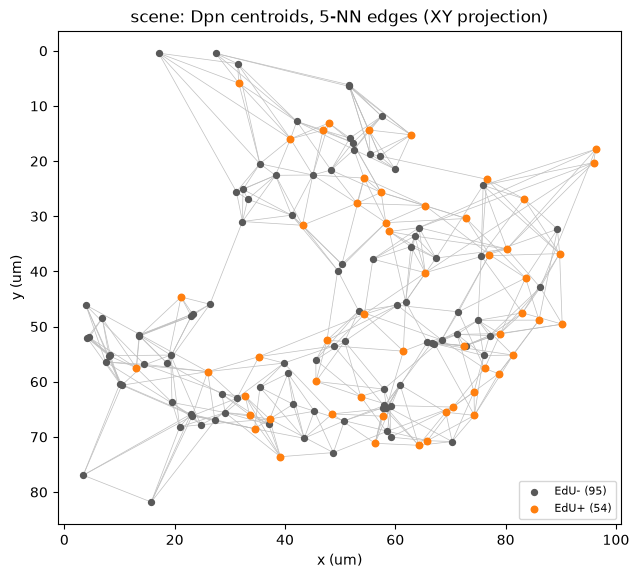

In [13]:
fig, axs = plt.subplots(1, len(graphs), figsize=(6.5 * len(graphs), 6), squeeze=False)
for ax, (region, g) in zip(axs[0], graphs.items()):
    p = g.pos.numpy()
    for s, t in g.edge_index.T.numpy():
        if s < t:
            ax.plot(p[[s, t], 2], p[[s, t], 1], color="0.75", lw=0.5, zorder=1)
    e = g.edu_pos.numpy()
    ax.scatter(p[~e, 2], p[~e, 1], s=18, c="0.35", label=f"EdU- ({(~e).sum()})", zorder=2)
    ax.scatter(p[e, 2], p[e, 1], s=22, c="tab:orange", label=f"EdU+ ({e.sum()})", zorder=3)
    ax.invert_yaxis(); ax.set_aspect("equal")
    ax.set_xlabel("x (um)"); ax.set_ylabel("y (um)")
    ax.set_title(f"{region}: Dpn centroids, {K_NEIGHBORS}-NN edges (XY projection)")
    ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

## 6. One limited question: do EdU+ Dpn objects neighbor each other more than expected?

**Statistic:** the fraction of undirected kNN edges whose two ends are both EdU+ (`pos_pos_edge_fraction`).

**Null:** shuffle `edu_pos` among the nodes of the same region `N_PERMUTATIONS` times. Positions, edges and the number of EdU+ objects stay fixed. The one-sided permutation p-value is `(1 + #null ≥ observed) / (1 + N_PERMUTATIONS)`.

Interpretation limits: this is **one series from one animal**. Cells are not independent biological replicates, EdU calls are unvalidated, Dpn recall against the 2D ground truth is well below 1, and without lobe labels the scene-level graph may mix regions with different biology.

,region,nodes,edu_pos,edges,observed_pos_pos_fraction,null_mean,null_2.5%,null_97.5%,obs_over_null_mean,p_one_sided
0,scene,149,54,465,0.146237,0.129827,0.109677,0.152688,1.126397,0.102949


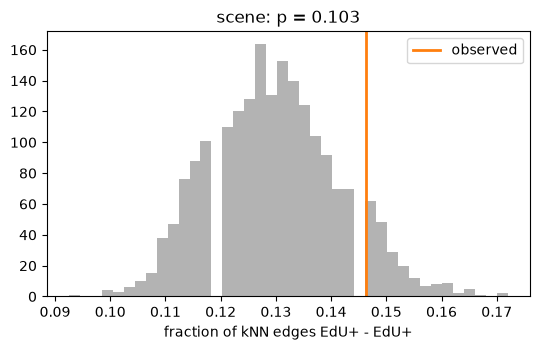

In [14]:
def pos_pos_fraction(edge_index, flag):
    s, t = edge_index
    keep = s < t
    return float((flag[s[keep]] & flag[t[keep]]).float().mean()) if keep.any() else float("nan")


perm_rows, nulls = [], {}
for region, g in graphs.items():
    flag = g.edu_pos
    if int(flag.sum()) < 2:  # no EdU+/EdU+ edge is possible; the test is undefined
        print(f"[{region}] {int(flag.sum())} EdU+ object(s): statistic undefined, skipped.")
        perm_rows.append({"region": region, "nodes": g.num_nodes, "edu_pos": int(flag.sum()), "edges": g.edge_index.shape[1] // 2})
        continue
    obs = pos_pos_fraction(g.edge_index, flag)
    null = np.array([pos_pos_fraction(g.edge_index, flag[torch.as_tensor(rng.permutation(g.num_nodes))]) for _ in range(N_PERMUTATIONS)])
    nulls[region] = null
    perm_rows.append({
        "region": region, "nodes": g.num_nodes, "edu_pos": int(flag.sum()),
        "edges": g.edge_index.shape[1] // 2,
        "observed_pos_pos_fraction": obs,
        "null_mean": null.mean(), "null_2.5%": np.percentile(null, 2.5), "null_97.5%": np.percentile(null, 97.5),
        "obs_over_null_mean": obs / null.mean() if null.mean() > 0 else np.nan,
        "p_one_sided": (1 + np.sum(null >= obs)) / (1 + N_PERMUTATIONS),
    })
perm = pd.DataFrame(perm_rows)
display(perm)

tested = [row for row in perm_rows if row["region"] in nulls]
fig, axs = plt.subplots(1, max(len(tested), 1), figsize=(5.5 * max(len(tested), 1), 3.6), squeeze=False)
for ax, row in zip(axs[0], tested):
    ax.hist(nulls[row["region"]], bins=40, color="0.7")
    ax.axvline(row["observed_pos_pos_fraction"], color="tab:orange", lw=2, label="observed")
    ax.set_xlabel("fraction of kNN edges EdU+ - EdU+")
    ax.set_title(f"{row['region']}: p = {row['p_one_sided']:.3f}")
    ax.legend()
plt.tight_layout()
plt.show()

### Exploratory: Scrib objects overlapping Dpn objects

Scrib labels are objects segmented in the Scrib channel. They are not assumed to be a cell type. This only tabulates how many Dpn objects have any Scrib object with IoS > 0.5, split by EdU status. It is descriptive and is not used anywhere else.

In [15]:
scrib_regions = RegionAnalyzer(ra_cfg).run(labels["Scrib"], metadata={**dpn_md, "channel_names": ["Scrib"]})
scrib_ov = oc.run(
    labels["Dpn"], labels["Scrib"],
    region_map=(region_map_from_dataframe(dpn_all, axes=["Z", "Y", "X"]), region_map_from_dataframe(scrib_regions.reset_index(), axes=["Z", "Y", "X"])),
    spacing=SPACING_ZYX,
)
scrib_ios = fmt.run(scrib_ov.metric("ios"))
scrib_ios.index = oid_to_label.loc[scrib_ios.index].to_numpy()
nodes["scrib_overlap"] = nodes["dpn_label"].map((scrib_ios > EDU_IOS_THRESHOLD).any(axis=1))
print(f"Scrib objects: {len(scrib_regions)}")
display(pd.crosstab([nodes["region"], nodes["edu_pos"]], nodes["scrib_overlap"], margins=True))

Scrib objects: 482


scrib_overlap   False  True  All
region edu_pos                  
scene  False       46    49   95
       True        15    39   54
All                61    88  149

### Save outputs

Everything goes to `OUT_DIR` under `/home/tqv9uu/vistiqlab/outputs/real_brain_pyg_pilot/`.

In [16]:
torch.save(graphs, OUT_DIR / "graphs.pt")
nodes.to_csv(OUT_DIR / "dpn_nodes.csv", index=False)
perm.to_csv(OUT_DIR / "permutation_summary.csv", index=False)
(OUT_DIR / "run_info.json").write_text(json.dumps({
    "animal": PREFIX, "raw_path": str(raw_path), "scene_index": SCENE_INDEX, "scene_name": scene_name,
    "batch_series_dir": str(series_dir), "spacing_zyx_um": SPACING_ZYX, "graph_level": GRAPH_LEVEL,
    "k_neighbors": K_NEIGHBORS, "edu_ios_threshold": EDU_IOS_THRESHOLD,
    "n_permutations": N_PERMUTATIONS, "seed": SEED, "feature_names": FEATURE_COLS,
}, indent=2))
print("Saved:", sorted(p.name for p in OUT_DIR.iterdir()))

reloaded = torch.load(OUT_DIR / "graphs.pt", weights_only=False)
assert all(torch.equal(reloaded[r].edge_index, graphs[r].edge_index) for r in graphs)
print("Reload check: OK")

Saved: ['dpn_nodes.csv', 'graphs.pt', 'permutation_summary.csv', 'run_info.json']
Reload check: OK


## 7. What training would require

**Repeat graph construction for all 12 animals.** Loop this notebook's steps over every manifest-matched series (and, once their anatomical relationship is understood, the other two series per animal). Use one graph per lobe once authoritative lobe labels exist for each series; scene-level graphs only as a stop-gap. Keep the same unit conventions (positive-Z µm centroids) and the same EdU rule, and record both in each graph's metadata.

**The animal is the unit of independence.** Every series, lobe, cell and slice from one animal must stay in the same train/validation/test group. With 12 animals, leave-one-animal-out (train on 11, test on 1, repeat 12 times) is the natural scheme. Choose hyperparameters in advance or tune them only inside the training animals, and report per-animal results next to any pooled summary.

**Do not train a graph classifier on a label derived from the statistic it is meant to discover.** Labelling lobes "clustered" by the permutation test above and then training a GNN to predict that label is circular: it can only rediscover the test. A graph-level task needs an independently recorded outcome (e.g. genotype, timepoint or condition), which this 24 h dataset does not provide on its own.

**If trying node-level EdU prediction:**
- the target is each Dpn object's `edu_pos`;
- `x` must contain no EdU-derived quantity (no EdU intensity, no `dpn_frac_in_edu`, no `max_ios_edu`, no overlap counts);
- neighbors' EdU labels must not be inputs either (no label propagation or neighbor-label features), unless the task is explicitly defined so that those labels are known at prediction time;
- EdU labels come from segmentation, so a manual EdU check on a sample is needed before treating them as targets.

**Compare against simple baselines** on the same leave-one-animal-out splits: logistic regression on the node's own features, plus the same model with local-density features (distance to the k-th neighbor, number of neighbors within a radius). A GNN is only interesting if it beats these, per animal, not just pooled.